**Yayika Tinner - 6722781026**

In [1]:
import sys
import numpy as np
import ml_dtypes

print(f"Python     : {sys.version}")
print(f"NumPy      : {np.__version__}")
print(f"ml_dtypes  : {ml_dtypes.__version__}")
print(f"Seeds used : 7 (PM2.5 year, Parts 1a/1b/3), 0 (weight layer, Parts 1c/2e)")
print(f"AI usage   : Claude for explanations, debugging help, reword my explanations, and checking my code & answers")

Python     : 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
NumPy      : 2.5.3
ml_dtypes  : 0.6.0
Seeds used : 7 (PM2.5 year, Parts 1a/1b/3), 0 (weight layer, Parts 1c/2e)
AI usage   : Claude for explanations, debugging help, reword my explanations, and checking my code & answers


## Part 1

### 1.a.

scale s = 6.8290 µg/m³ per bucket
year RMSE = 1.9795 µg/m³
calm season uses 20/127 buckets


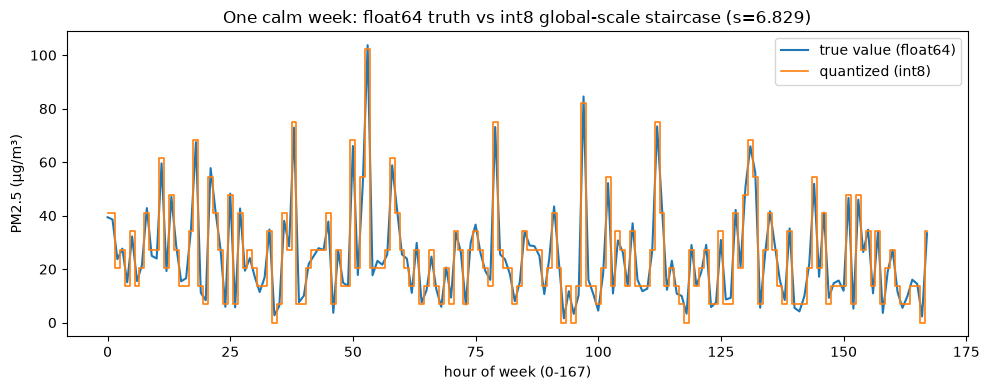

In [2]:
# global scale

import numpy as np
import matplotlib.pyplot as plt

# generate the seeded data
rng = np.random.default_rng(7)              # seed = 7, starting point, run again get same sequence
pm = rng.gamma(2.0, 12.5, 8760)             # normal data -> 1 year, hourly PM -> 365*24=8760
pm[1400:2200] += rng.gamma(4.0, 60.0, 800)  # burning ss -> feb-mar -> 2200-1400=800 data spikes (hours 1401-2200)
pm = pm[:8736]                              # trim to first 52 weeks

def rmse(e):                                # rmse func
    return np.sqrt(np.mean(e ** 2))

# global scale, quantize, dequantize
s = np.abs(pm).max() / 127.0                # s, scale -> max/ruler width (max from all including burning)
q = np.round(pm / s)                        # q, quantizee -> map to the ruler
deq = q * s                                 # deq, dequantize -> map back, have error from rounding

# year RMSE
year_rmse = rmse(deq - pm)                  

# how many buckets does the calm season use?
calm = pm[3000:]                                        # after burning season
calm_buckets = len(np.unique(np.round(calm / s)))       # how many ruler values actually use?

print(f"scale s = {s:.4f} µg/m³ per bucket")
print(f"year RMSE = {year_rmse:.4f} µg/m³")
print(f"calm season uses {calm_buckets}/127 buckets")

# plot one calm week
week_start = 3000                                       # pick calm week (within pm[3000:])
week = slice(week_start, week_start + 168)              # 168 hours = 1 week

plt.figure(figsize=(10, 4))
plt.plot(pm[week], label="true value (float64)", linewidth=1.5)
plt.step(range(168), deq[week], where="mid", label="quantized (int8)", linewidth=1.2)
plt.xlabel("hour of week (0-167)")
plt.ylabel("PM2.5 (µg/m³)")
plt.title(f"One calm week: float64 truth vs int8 global-scale staircase (s={s:.3f})")
plt.legend()
plt.tight_layout()
plt.show()

### 1.b.

In [3]:
# per-block scales

def quant_blocks(x, B):                                     # B = num of columns, blocks
    xr = x.reshape(-1, B)                                   # dim = k*B
    sb = np.abs(xr).max(axis=1, keepdims=True) / 127.0      # scale per block, axis=1 colapes on column
    deq_blocks = np.round(xr / sb) * sb
    return deq_blocks.ravel()                               # 1D array, 1*8736

block_sizes = {         # B values
    "year":  8736,
    "month": 728,
    "week":  168,       # 7*24 = 168 hrs, 52*168 = 8736 data, -> 52 rows, 168 cols -> row = week, col = hour
    "day":   24,
}

print(f"{'block':<8}{'B':>6}{'calm RMSE':>12}{'bits/value':>12}")       # table header, <left, >right, characters

for name, B in block_sizes.items():
    deq_b = quant_blocks(pm, B)
    calm_rmse_b = rmse((deq_b - pm)[3000:])                             # same calm season slice as 1.a
    bits = 8 + 32 / B                                                   # Ch.3, p.40
    print(f"{name:<8}{B:>6}{calm_rmse_b:>12.4f}{bits:>12.3f}")

block        B   calm RMSE  bits/value
year      8736      1.9810       8.004
month      728      0.2511       8.044
week       168      0.2122       8.190
day         24      0.1563       9.333


With a 9.0 bit budget, I will use scale per week (B=168), since the RMSE is the lowest, while the number of bits used is under the limit and not much higher than other methods.

### 1.c.

In [4]:
#  int4 quantization, per-tensor vs per-block-of-32

rng = np.random.default_rng(0)
W = rng.normal(0, 0.05, (256, 256))                                         # 65,536 weights, 0=mean, 0.05=SD, most ~ -0.15 - 0.15
W.flat[rng.choice(W.size, 8, replace=False)] = rng.choice([-2.0, 2.0], 8)   # choose 8 data from W, change to 2 or -2 (outlier)

x = rng.normal(0, 1.0, 256)                                     # test input
y_true = W @ x                                                  # true, unquantized values

# per-tensor: one scale for the whole 256x256 matrix
s_tensor = np.abs(W).max() / 7.0
Wt = np.clip(np.round(W / s_tensor), -7, 7) * s_tensor

# per-block-of-32: one scale per group of 32 weights
Wb = W.reshape(-1, 32)
s_block = np.abs(Wb).max(axis=1, keepdims=True) / 7.0
W_block = (np.clip(np.round(Wb / s_block), -7, 7) * s_block).reshape(W.shape)

for name, Wq in [("per-tensor", Wt), ("block-32", W_block)]:
    y = Wq @ x
    cos = (y @ y_true) / (np.linalg.norm(y) * np.linalg.norm(y_true))
    print(f"{name:<10}: cosine {cos:.5f}   weight RMSE {rmse(Wq - W):.5f}")

per-tensor: cosine 0.32612   weight RMSE 0.04960
block-32  : cosine 0.99307   weight RMSE 0.00576


It wasn't per-tensor quantization that broke the layer, it was the 8 outliers. They set the scale for everyone, so ordinary weights lost almost all their resolution, and weight RMSE completely missed it because the damage only shows up in the output, not the storage.

### 1.d.

Part 1(c) shows why q4_K_M is designed the way it is. Using one shared scale to quantize all the weights seems like the simplest approach, but it doesn't work well. With a single scale across all 65,536 weights, the output cosine dropped to 0.326, close to random noise, because 8 outlier weights alone set the scale and ruined the resolution for every normal weight. Splitting the weights into groups of 32, each with its own scale, fixed this, raising the cosine back to 0.993, at only a small storage cost. q4_K_M works the same way. It groups weights into blocks of 32 inside larger superblocks of 256, so each block gets its own scale and an outlier only affects its own block instead of the entire layer. The block size of 32 isn't inherently correct, it's just the tradeoff between accuracy and storage that q4_K_M's designers chose, the same tradeoff I measured directly in Part 1(b).

## Part 2

### 2.a.

Range: Neural network weights are typically small, bounded values, similar to what I saw in Part 1(c) where ordinary weights sat close to 0, so we don't need floating point's huge range, and an integer format with a scale is enough.

Precision: q4_K_M passes 3 of 4 probes and only got partial on the Thai-language one, while q2_K fails on 2 probes and q8_0 passes all 4; q8_0's extra safety margin costs twice the storage of q4_K_M for a difference of just one partial score, so q4_K_M is the most compressed option that still stays reliable.

Cost: q4_K_M uses about a third of fp16's storage and is even faster than fp16 (285 vs 186 tok/s), fitting comfortably on an 8GB laptop with no GPU; q8_0 would also fit, but its extra 134MB isn't worth paying for when q4_K_M's only weakness is a slightly imperfect Thai sentence, and q2_K's further savings aren't worth its 2 failures.

### 2.b.

In [5]:
import pandas as pd

df = pd.read_csv("ref-bakeoff.csv", comment="#")
print(df)

     tier  disk_mb  tok_s_run1  tok_s_run2  tok_s_run3  tok_s_median  \
0    fp16      994       184.6       185.8       185.8         185.8   
1    q8_0      531       274.7       275.0       275.1         275.0   
2  q4_K_M      397       286.4       285.4       277.3         285.4   
3    q2_K      338       296.7       302.0       303.8         302.0   

  p1_language p2_arithmetic p3_recall p4_instruction  \
0         ref           ref       ref            ref   
1        pass          pass      pass           pass   
2     partial          pass      pass           pass   
3        fail          fail      pass           pass   

                                               notes  
0               the reference output for every probe  
1               identical to fp16 on all four probes  
2  Thai script but semantic nonsense (PM2.5 as 'a...  
3  arithmetic drifts 401 to 409; mixes Chinese in...  


In [6]:
import numpy as np
import matplotlib.pyplot as plt

fp16_size = df.loc[df.tier == "fp16", "disk_mb"].values[0]
fp16_speed = df.loc[df.tier == "fp16", "tok_s_median"].values[0]

sizes_theory = np.linspace(df.disk_mb.min() * 0.9, df.disk_mb.max() * 1.05, 100)
speed_law = fp16_speed * fp16_size / sizes_theory   # calculate predicted speed from the size, speed*size = constant

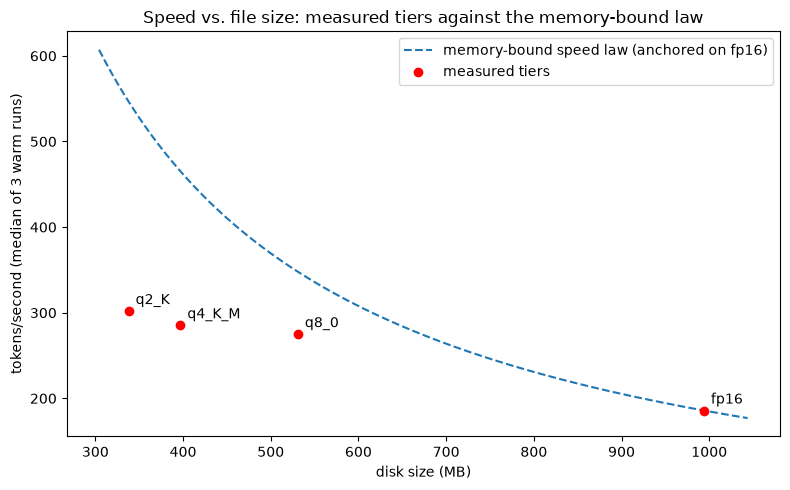

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(sizes_theory, speed_law, linestyle="--", label="memory-bound speed law (anchored on fp16)")    # calculated
plt.scatter(df.disk_mb, df.tok_s_median, color="red", zorder=5, label="measured tiers")                 # measured

for _, row in df.iterrows():
    plt.annotate(row.tier, (row.disk_mb, row.tok_s_median), textcoords="offset points", xytext=(5, 5))

plt.xlabel("disk size (MB)")
plt.ylabel("tokens/second (median of 3 warm runs)")
plt.title("Speed vs. file size: measured tiers against the memory-bound law")
plt.legend()
plt.tight_layout()
plt.show()

All three quantized tiers measure below the memory-bound speed law, and the gap grows as the file shrinks (q8_0 is 72.8 tok/s under the prediction, q4_K_M is 179.8 under, q2_K is 244.4 under), because some part of inference time is a fixed per-token cost that doesn't shrink along with the file size, so halving the size doesn't fully double the speed.

q2_K gets 2 of the 4 test questions wrong, instead of writing one clean Thai sentence, it starts mixing in Chinese characters and keeps rambling until it hits the output limit, and instead of correctly computing 17×23, its answer drifts off to 409. q4_K_M, despite also being compressed, still gets the arithmetic exactly right and stays in the correct language, so q2_K isn't just slightly less polished, it's actually giving wrong answers.

### 2.c.

q4_K_M (397MB) plus ~1GB (1024MB) runtime overhead is about 1.4GB, fitting within the laptop's ~4–5GB of free RAM after the OS and browser.

### 2.d.

**Probe 1: Language (Thai, translation)**  
```
Prompt: "Translate this sentence into Thai: 'I need to buy three eggs and a bottle of water.'"
```  
Criterion:  
- pass = accurate, fluent Thai translation matching the fp16 reference's meaning and vocabulary choices  
- partial = correct meaning but awkward phrasing or a minor word-choice difference from the fp16 reference  
- fail = wrong meaning, mixes in non-Thai script, or fails to stop generating.  

What it catches: whether compression damages the model's ability to hold onto meaning and vocabulary precisely while switching languages, rather than just producing fluent-sounding but disconnected Thai text.

**Probe 2: Arithmetic (word problem)**
```  
Prompt: "If a bag of rice costs 45 baht and I buy 6 bags, how much do I pay in total? Reply with the number only."
```  
Criterion:  
- pass = exact numeric match to the fp16 reference's answer  
- partial = off by a small, explainable amount (e.g., an off-by-one error)  
- fail = wildly different or non-numeric.  

What it catches: whether compression damages the model's ability to first identify the correct operation from a real-world context, not just execute a bare multiplication it was directly handed.

**Probe 3: Recall**
```  
Prompt: "What gas do plants absorb during photosynthesis? One word."
```  
Criterion:  
- pass = matches the fp16 reference's answer exactly  
- fail = wrong or missing.  

What it catches: whether compression causes the model to lose or garble a specific, memorized factual detail, separate from its ability to reason or generate fluent language.

**Probe 4: Instruction-following**
```  
Prompt: "List the first five positive odd numbers, comma-separated."
```  
Criterion:  
- pass = exactly 1, 3, 5, 7, 9, correctly comma-separated, matching the fp16 reference's format  
- partial = correct numbers but wrong formatting (e.g., missing commas, written as a sentence)  
- fail = wrong or missing numbers.  

What it catches: whether compression damages the model's ability to follow a precise structural/formatting instruction, separate from whether its underlying content knowledge is correct.

### 2.e.

In [8]:
# 1.c but change int4 to int8

# 1 - setup + quantize + bytes saved

rng = np.random.default_rng(0)                      # same seed as before
W = rng.normal(0, 0.05, (256, 256))
W.flat[rng.choice(W.size, 8, replace=False)] = rng.choice([-2.0, 2.0], 8)
x = rng.normal(0, 1.0, 256)
y_true = W @ x

Wb = W.reshape(-1, 32)
s_block8 = np.abs(Wb).max(axis=1, keepdims=True) / 127.0
W_block8 = (np.clip(np.round(Wb / s_block8), -127, 127) * s_block8).reshape(W.shape)

n_weights = W.size
n_blocks = n_weights // 32
original_bytes = n_weights * 4
quantized_bytes = n_weights * 1 + n_blocks * 4
bytes_saved = original_bytes - quantized_bytes

print(f"original size   : {original_bytes:,} bytes")
print(f"quantized size  : {quantized_bytes:,} bytes")
print(f"bytes saved     : {bytes_saved:,} bytes ({bytes_saved / original_bytes:.1%} smaller)")

original size   : 262,144 bytes
quantized size  : 73,728 bytes
bytes saved     : 188,416 bytes (71.9% smaller)


In [9]:
# 2 - output cosine

y = W_block8 @ x
cos = (y @ y_true) / (np.linalg.norm(y) * np.linalg.norm(y_true))       # from Math3 a·b = ||a||*||b||*cos(θ)
print(f"output cosine   : {cos:.5f}")

# int4 -> cosine 0.99307
# int8 -> cosine 0.99998 (closer to 1.0 since int8's 127 slots give finer resolution per block than int4's 7)

output cosine   : 0.99998


### 2.f.

I recommend installing the **q4_K_M** version of the study assistant because of the following reasons:

1. q4_K_M is 397MB, ~40% the size of the uncompressed model (994MB), which matters on an 8GB laptop with limited memory. q4_K_M runs faster, ~285.4 tokens/s vs ~185.8 tokens/s for the uncompressed model, which matters on a device with no dedicated graphics processor.

2. On the 4 test questions (language, arithmetic, recall, and instructions), q4_K_M passed 3 and got 1 partial on the Thai-language question. It stayed fluent and grammatically correct, but the actual content came out a bit odd, for example describing PM2.5 as an extract of human laughter instead of an air pollutant, so the language itself wasn't broken, just the meaning.

3. I also tested this same block-based compression method myself, on a smaller 256\*256 example layer with 8 planted outlier weights, and measured a cosine similarity of 0.99998, meaning the compressed layer's output was almost identical to the uncompressed one, confirming q4_K_M preserves nearly all of the model's real behavior even with outlier values.

q2_K fails 2 of the 4 questions, its arithmetic drifts from 401 to 409 instead of giving the correct answer, and its Thai output mixes in another language eventhough specified to only use Thai. This is a functional breakdown, not just a minor quality issue, so I don't recommend using q2_K despite it being smaller and faster than q4_K_M.

One limitation from the 4 probes is that, it is only enough to catch clear failures but not enough to guarantee reliability on every topic students might ask, I recommend making the test cover more subjects before using it on every laptop.

## Part 3

### 3.a.

In [10]:
import numpy as np

def to_q15(x):
    return np.int16(np.round(np.clip(x, -1, 32767 / 32768) * 32768))        # sensor reading -> 16 bit

def from_q15(q):
    return np.asarray(q, dtype=np.float64) / 32768.0                        # 16 bit -> sensor reading

def q15_mul(a, b):     # int32 to avoid overflow, /2^15 because denominator multiply eachother too -> need 1 more
    return np.int16((np.int32(a) * np.int32(b)) >> 15)                      # 16 bit * 16 bit -> 16 bit

# round-trip 0.7
q = to_q15(0.7)
recovered = from_q15(q)
print(f"0.7 stored as {q}, recovered as {recovered}")

error = recovered - 0.7
tick = 1 / 32768
print(f"round-trip error: {error:.10f}")
print(f"error as a fraction of one tick: {error / tick:.3f}")

# sanity check q15_mul
print("0.7 * 0.6 =", from_q15(q15_mul(to_q15(0.7), to_q15(0.6))))           # should be ~0.42

0.7 stored as 22938, recovered as 0.70001220703125
round-trip error: 0.0000122070
error as a fraction of one tick: 0.400
0.7 * 0.6 = 0.41998291015625


### 3.b.

In [11]:
# run the given pipeline at the 48 hour window

W = 48
qs = to_q15(pm / 1024.0)                                                # dec -> 16 bit
cs = np.cumsum(qs, dtype=np.int16)                                      # cumulative sum
sums16 = cs[W - 1:] - np.concatenate(([np.int16(0)], cs[:-W]))          # sliding window, array of 48 hr sum

avg_mcu = from_q15(sums16 // W) * 1024.0                                # dashboard published (hw limitation)
truth = np.convolve(pm, np.ones(W) / W, "valid")                        # use real float64 to calculate, REAL VALUE


# find the worst window

errors = np.abs(avg_mcu - truth)
worst_idx = np.argmax(errors)                                           # gives position with max error

print(f"worst window at hour {worst_idx}:")
print(f"  truth     = {truth[worst_idx]:.4f}")
print(f"  published = {avg_mcu[worst_idx]:.4f}")
print(f"  error     = {errors[worst_idx]:.4f}")


# count negative published averages

n_negative = np.sum(avg_mcu < 0)
print(f"\nnegative averages published this year: {n_negative}")

worst window at hour 1434:
  truth     = 281.1363
  published = -17.5625
  error     = 298.6988

negative averages published this year: 7581


In [12]:
# print("pm     :", pm)           # dec
# print("qs     :", qs)           # dec -> 16 bit
# print("cs     :", cs)           # cum sum of qs
# print("sums16 :", sums16)       # sum of 48 hr window

In [13]:
# print(sum(qs[0:24]))
    # 15014

# print(sum(qs[0:48]))
    # -32425 -> 48 hr = overflow
    # C:\Users\yayik\AppData\Local\Temp\ipykernel_26680\4200022716.py:5: RuntimeWarning: overflow encountered in scalar add

In [14]:
# print("avg_mcu:", avg_mcu)
# print("truth  :", truth)

### 3.c.

In [15]:
typical_calm = np.mean(pm[3000:])
print(typical_calm)

25.14807757055747


A typical calm reading of about 25 µg/m³ gets pre-scaled into Q15's range by 25/1024 = 0.0244, then converted to a q15 integer by 0.0244*32768 = 800. Summing 24 of these gives 800(24) = 19,200, which stays safely under int16's ceiling of 2¹⁵-1 = 32,767, but summing 48 of them gives 800(48) = 38,400, which overflows that same ceiling (38,400 > 32,767). This is why the 24 hour version survived calm air while the 48 hour version doesn't, doubling the window doubled the sum without doubling the storage box that has to hold it.

### 3.d.

In [16]:
# fix by widening the accumulator to int32

W = 48
qs = to_q15(pm / 1024.0)
cs32 = np.cumsum(qs, dtype=np.int32)                                            # int16 -> int32 (only change)
sums16_fixed = cs32[W - 1:] - np.concatenate(([np.int32(0)], cs32[:-W]))
avg_mcu_fixed = from_q15(sums16_fixed // W) * 1024.0

errors_fixed = np.abs(avg_mcu_fixed - truth)
max_error_fixed = errors_fixed.max()
one_tick = (1 / 32768) * 1024

print(f"maximum error after fix    : {max_error_fixed:.6f}")
print(f"size of one un-scaled tick : {one_tick:.6f}")
print(f"negative averages after fix: {np.sum(avg_mcu_fixed < 0)}")              # 0 -> fixed

maximum error after fix    : 0.034861
size of one un-scaled tick : 0.031250
negative averages after fix: 0


### 3.e.

The rule is: keep each individual reading stored small (int16), but always add them into something bigger (int32), because a running total keeps growing while a single reading never does.

This is the same problem as the fp16/bf16 demo: a year of PM2.5 readings summed in fp16 grew past what fp16 could hold at all and turned into infinity, and summed in bf16 it didn't run out of room, but got stuck once the gaps between representable numbers grew wider than a single reading, so it silently froze partway through the year, the q15 fix follows the identical pattern, just with integers instead of floats.

### 3.f.

In [17]:
a = np.array([to_q15(0.9)], dtype=np.int16)
print("wraparound:", from_q15((a + a)[0]))           # 0.9 + 0.9 = -0.20001220703125 (wrapped around to negative)

sat = np.clip(np.int32(a) + np.int32(a), -32768, 32767).astype(np.int16)
print("saturation:", from_q15(sat[0]))               # 0.9 + 0.9 = 0.999969482421875 (capped at <1)

wraparound: -0.20001220703125
saturation: 0.999969482421875


I would burn saturation into the firmware, because wrapping a high pollution reading into a negative number makes a dangerous air-quality day look artificially safe, the same danger as a motor controller wrapping to full negative torque, a failure serious enough to cause a recall.